# **Neural Networks from scratch and in PyTorch** (corrected edition)

Changes with respect to `Neural_Network_original.ipynb`:

1. **The 2-2-1 "neural network" of the regression part had no activation function.** Without a non-linearity, $\hat y=w_{21}(w_{11}x_1+w_{13}x_2+b_{11})+w_{22}(\dots)+b_2$ is just a linear model in $x$; the network cannot do more than linear regression (and the PyTorch `SimpleNN` had the same problem). Here the linear version is kept on purpose, to show this, and a ReLU version is added in all three implementations (loop, vectorised, PyTorch).
2. The loop version with ReLU plotted `loss_history` of the *previous* (linear) run; it now records its own losses.
3. Weights are random without a seed (results changed on every run); all random numbers are seeded.
4. In the classification part the gradient was the gradient of the *sum* of the losses but the printed loss was the *mean*, so `lr=0.01` was in fact `lr=4` on the mean. The code below divides by $m$.
5. `nn.Sigmoid` + `nn.BCELoss` is replaced by raw logits + `nn.BCEWithLogitsLoss` (numerically stable).
6. Wrong comments fixed ("2 hidden neurons", "Should print (500, 2)"); the "validation" loss was computed on the test set and is renamed; the `Bin_packing.csv` part is skipped when the file is not present.

In [1]:
import numpy as np, matplotlib.pyplot as plt, torch, torch.nn as nn
from sklearn.datasets import make_regression, make_classification
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

np.random.seed(0); torch.manual_seed(0)
X, y = make_regression(n_samples=100, n_features=2, noise=10, random_state=42)
y = y.reshape(-1, 1)
X = (X - X.mean(axis=0)) / X.std(axis=0)
y = (y - y.mean()) / y.std()
print(X.shape, y.shape)

(100, 2) (100, 1)


## **Regression: 2 -> 2 -> 1**

Notation of the slides: $a_1=g(x_1w_{11}+x_2w_{13}+b_{11})$, $a_2=g(x_1w_{12}+x_2w_{14}+b_{12})$, $\hat y=a_1w_{21}+a_2w_{22}+b_2$ (linear output for regression).

OLS mse                   : 0.01022
2-2-1 without activation  : 0.01022  (identical: the network is a linear model)
effective coefficients W1@W2 = [0.6906 0.6942]  OLS: [0.6906 0.6942]
2-2-1 with ReLU           : 0.00951  (the data are linear, so there is nothing to gain)


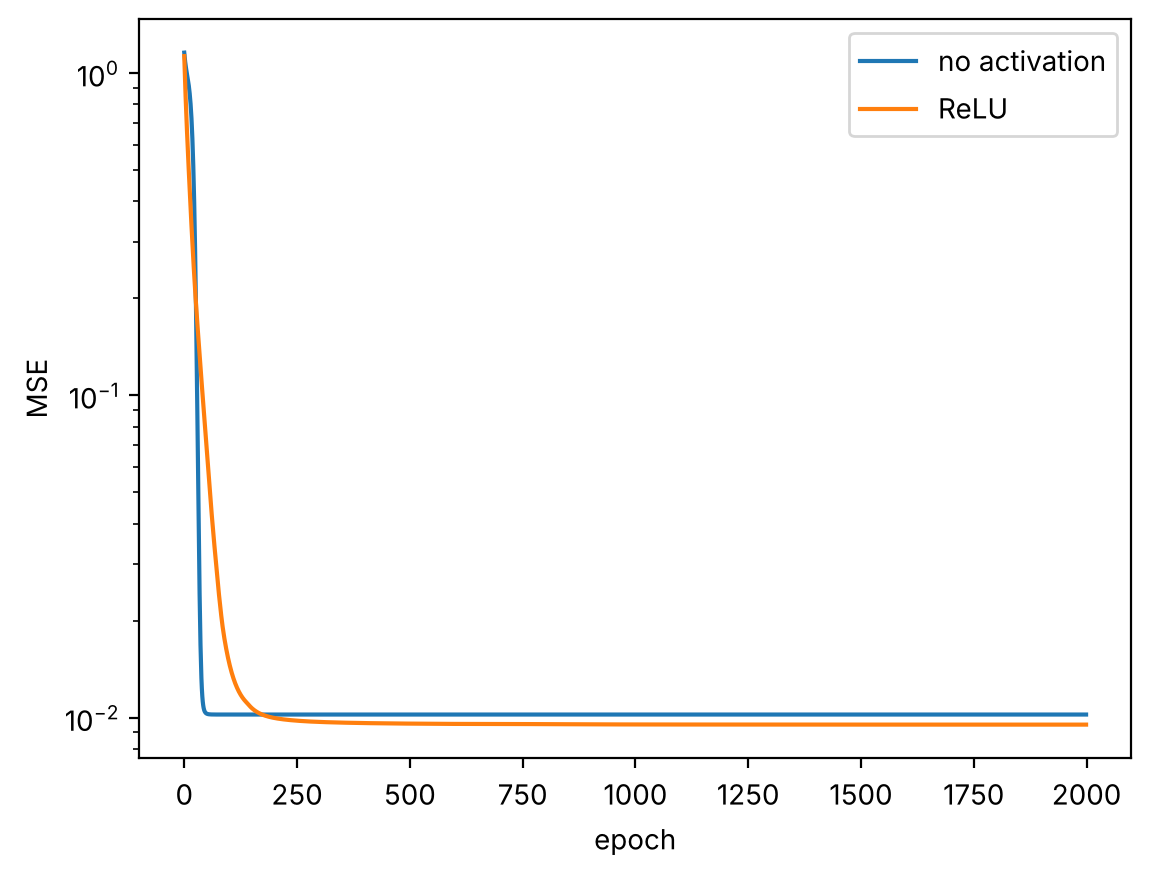

In [2]:
def train_221(X, y, activation, lr=0.05, epochs=2000, seed=0):
    """Full-batch gradient descent, one sample at a time written out as in the lecture (but vectorised over samples)."""
    rng = np.random.default_rng(seed)
    W1, b1 = rng.normal(0, 0.5, (2, 2)), np.zeros((1, 2))     # columns: neuron a1, a2
    W2, b2 = rng.normal(0, 0.5, (2, 1)), np.zeros((1, 1))
    g  = {"linear": lambda z: z, "relu": lambda z: np.maximum(0, z)}[activation]
    dg = {"linear": lambda z: np.ones_like(z), "relu": lambda z: (z > 0) * 1.0}[activation]
    m, hist = len(X), []
    for _ in range(epochs):
        Z1 = X @ W1 + b1; A1 = g(Z1); yh = A1 @ W2 + b2
        hist.append(np.mean((yh - y) ** 2))
        dy = 2 * (yh - y) / m                                    # dL/dyhat for the MEAN loss
        dW2, db2 = A1.T @ dy, dy.sum(0, keepdims=True)
        dZ1 = (dy @ W2.T) * dg(Z1)
        dW1, db1 = X.T @ dZ1, dZ1.sum(0, keepdims=True)
        W1 -= lr * dW1; b1 -= lr * db1; W2 -= lr * dW2; b2 -= lr * db2
    return (W1, b1, W2, b2), hist

params_lin, h_lin = train_221(X, y, "linear")
params_relu, h_relu = train_221(X, y, "relu", seed=3)
ols = LinearRegression().fit(X, y)
print("OLS mse                   :", round(float(np.mean((ols.predict(X) - y) ** 2)), 5))
print("2-2-1 without activation  :", round(h_lin[-1], 5), " (identical: the network is a linear model)")
print("effective coefficients W1@W2 =", (params_lin[0] @ params_lin[2]).ravel().round(4), " OLS:", ols.coef_.ravel().round(4))
print("2-2-1 with ReLU           :", round(h_relu[-1], 5), " (the data are linear, so there is nothing to gain)")
plt.plot(h_lin, label="no activation"); plt.plot(h_relu, label="ReLU"); plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

### The same in PyTorch (with an activation, a train/validation split and a fixed seed)

In [3]:
X2, y2 = make_regression(n_samples=1000, n_features=2, noise=10, random_state=42)
y2 = y2.reshape(-1, 1)
X2 = (X2 - X2.mean(0)) / X2.std(0); y2 = (y2 - y2.mean()) / y2.std()
X_train, X_val, y_train, y_val = train_test_split(X2, y2, test_size=0.2, random_state=42)

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)
t = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
Xt, yt, Xv, yv = t(X_train), t(y_train), t(X_val), t(y_val)

class SimpleNN(nn.Module):
    def __init__(self, activation=True):
        super().__init__()
        self.hidden = nn.Linear(2, 2); self.output = nn.Linear(2, 1)
        self.act = nn.ReLU() if activation else nn.Identity()
    def forward(self, x):
        return self.output(self.act(self.hidden(x)))

def fit(model, lr=0.05, epochs=300):
    model.to(device); opt = torch.optim.SGD(model.parameters(), lr=lr); crit = nn.MSELoss(); tr, va = [], []
    for _ in range(epochs):
        model.train(); opt.zero_grad(); loss = crit(model(Xt), yt); loss.backward(); opt.step(); tr.append(loss.item())
        model.eval()
        with torch.no_grad(): va.append(crit(model(Xv), yv).item())
    return tr, va

for name, act in [("no activation", False), ("ReLU", True)]:
    torch.manual_seed(0)
    tr, va = fit(SimpleNN(act))
    print(f"{name:14s} train MSE {tr[-1]:.4f}  validation MSE {va[-1]:.4f}")

device: cpu


no activation  train MSE 0.0560  validation MSE 0.0606
ReLU           train MSE 0.0682  validation MSE 0.0904


## **Classification: 2 -> 2 -> 1 in NumPy** (ReLU hidden layer, sigmoid output, binary cross-entropy)

For the sigmoid output with cross-entropy loss the gradient with respect to the logit is simply $\hat y-y$ (see the chapter).

(400, 2) (400, 1) (100, 2)


2-2-1: test accuracy over 10 seeds: mean 0.887, min 0.870, max 0.910


2-10-1: test accuracy over 10 seeds: mean 0.932, min 0.920, max 0.950


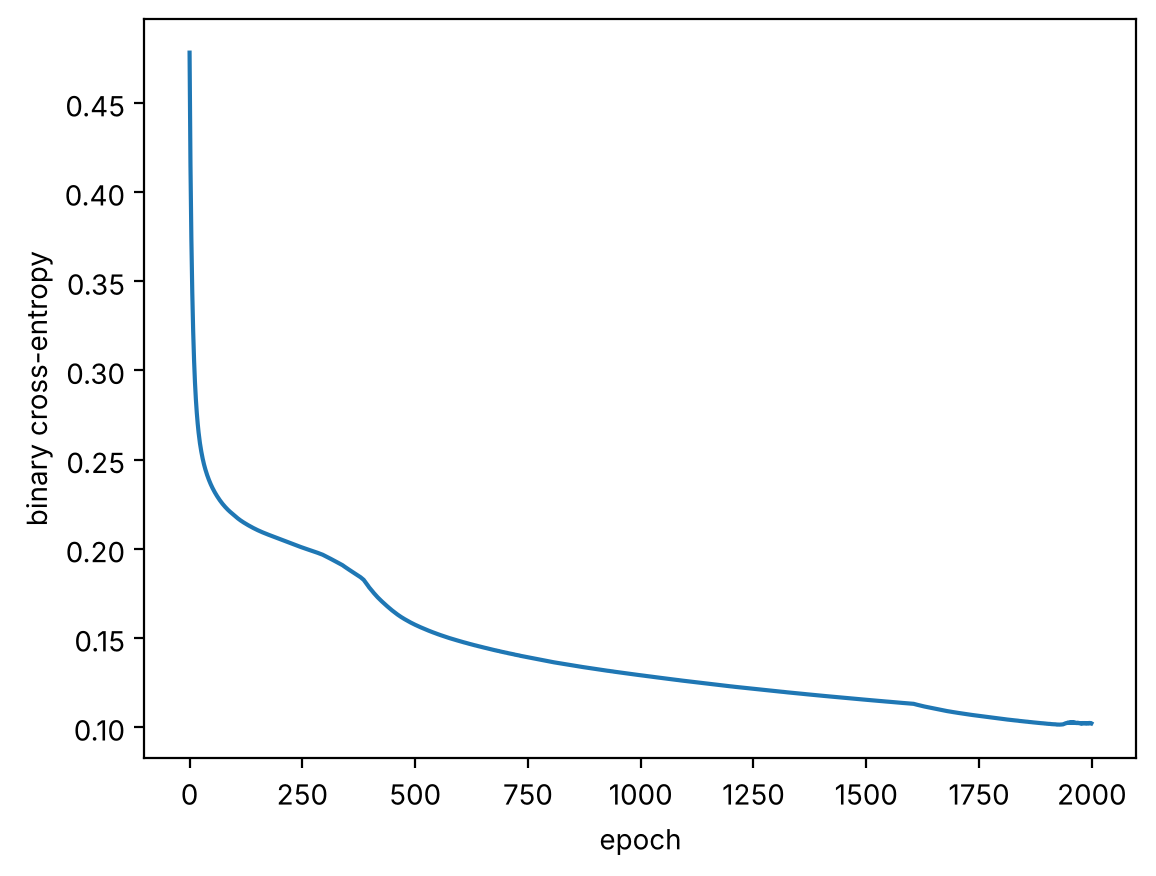

In [4]:
Xc, yc = make_classification(n_samples=500, n_features=2, n_informative=2, n_redundant=0, n_classes=2, random_state=42)
yc = yc.reshape(-1, 1)
Xa, Xb, ya, yb = train_test_split(Xc, yc, test_size=0.2, random_state=42)
print(Xa.shape, ya.shape, Xb.shape)          # (400, 2) (400, 1) (100, 2)

def sigmoid(z): return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def train_cls(Xa, ya, hidden=2, lr=0.5, epochs=2000, seed=0):
    rng = np.random.default_rng(seed)
    W1, b1 = rng.normal(0, 0.5, (2, hidden)), np.zeros((1, hidden))
    W2, b2 = rng.normal(0, 0.5, (hidden, 1)), np.zeros((1, 1))
    m, hist = len(Xa), []
    for _ in range(epochs):
        Z1 = Xa @ W1 + b1; A1 = np.maximum(0, Z1); p = sigmoid(A1 @ W2 + b2)
        hist.append(-np.mean(ya * np.log(p + 1e-12) + (1 - ya) * np.log(1 - p + 1e-12)))
        dZ2 = (p - ya) / m                                       # sigmoid + cross-entropy
        dW2, db2 = A1.T @ dZ2, dZ2.sum(0, keepdims=True)
        dZ1 = (dZ2 @ W2.T) * (Z1 > 0)
        dW1, db1 = Xa.T @ dZ1, dZ1.sum(0, keepdims=True)
        W1 -= lr * dW1; b1 -= lr * db1; W2 -= lr * dW2; b2 -= lr * db2
    return (W1, b1, W2, b2), hist

def predict(params, X):
    W1, b1, W2, b2 = params
    return sigmoid(np.maximum(0, X @ W1 + b1) @ W2 + b2)

for hidden in (2, 10):
    accs = []
    for seed in range(10):
        params, hist = train_cls(Xa, ya, hidden=hidden, seed=seed)
        accs.append(np.mean((predict(params, Xb) >= 0.5) == yb))
    print(f"2-{hidden}-1: test accuracy over 10 seeds: mean {np.mean(accs):.3f}, min {np.min(accs):.3f}, max {np.max(accs):.3f}")
plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("binary cross-entropy"); plt.show()

## **Classification in PyTorch** (2 -> 10 -> 5 -> 1)

The model returns **logits**; `BCEWithLogitsLoss` applies the sigmoid inside the loss in a numerically stable way, and the sigmoid is applied only when probabilities are needed. The curves are train loss and *test* loss (the original called the latter "validation"; with the test set used for monitoring, it must not be used to tune hyper-parameters).

test accuracy 0.880
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        50
           1       0.84      0.94      0.89        50

    accuracy                           0.88       100
   macro avg       0.89      0.88      0.88       100
weighted avg       0.89      0.88      0.88       100

[[41  9]
 [ 3 47]]


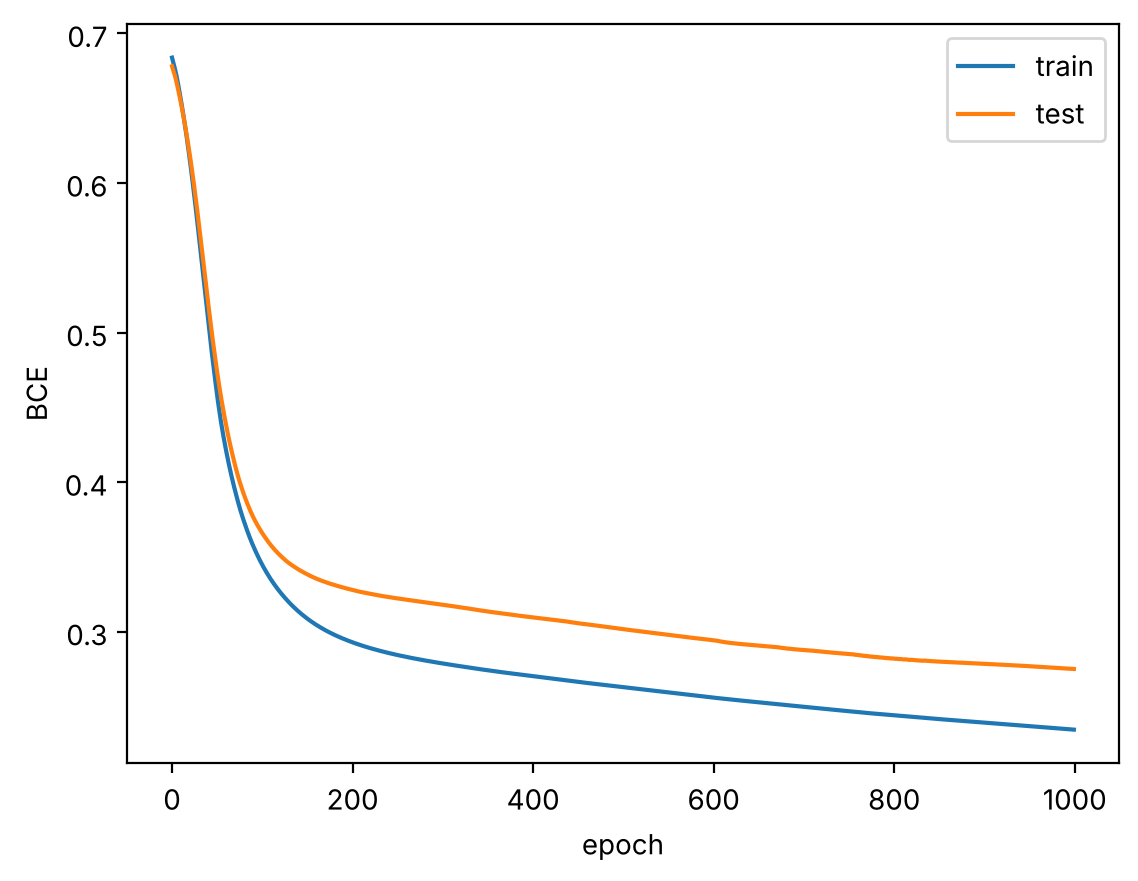

In [5]:
class SimpleNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(2, 10)       # 2 input features -> 10 hidden neurons
        self.hidden_2 = nn.Linear(10, 5)
        self.act_1, self.act_2 = nn.ReLU(), nn.LeakyReLU()
        self.output = nn.Linear(5, 1)        # logits
    def forward(self, x):
        return self.output(self.act_2(self.hidden_2(self.act_1(self.hidden(x)))))

def run(model, Xtr, ytr, Xte, yte, lr, epochs):
    model.to(device); crit = nn.BCEWithLogitsLoss(); opt = torch.optim.SGD(model.parameters(), lr=lr)
    Xtr_, ytr_, Xte_, yte_ = t(Xtr), t(ytr), t(Xte), t(yte); tr, te = [], []
    for _ in range(epochs):
        model.train(); opt.zero_grad(); loss = crit(model(Xtr_), ytr_); loss.backward(); opt.step(); tr.append(loss.item())
        model.eval()
        with torch.no_grad(): te.append(crit(model(Xte_), yte_).item())
    model.eval()
    with torch.no_grad(): pred = (torch.sigmoid(model(Xte_)).cpu().numpy() >= 0.5).astype(int)
    return tr, te, pred

torch.manual_seed(0)
tr, te, pred = run(SimpleNNClassifier(), Xa, ya, Xb, yb, lr=0.1, epochs=1000)
print(f"test accuracy {np.mean(pred == yb):.3f}")
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(yb, pred)); print(confusion_matrix(yb, pred))
plt.plot(tr, label="train"); plt.plot(te, label="test"); plt.xlabel("epoch"); plt.ylabel("BCE"); plt.legend(); plt.show()

## **A deeper network: 100 features, 2 of them informative**

`make_classification(n_features=100, n_informative=2)`: 98 columns are noise. The comment of the original ("should print (500, 2)") was a leftover from the previous cell.

(8000, 100) (2000, 100)  majority-class baseline: 0.505
DNNClassifier(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=20, bias=True)
    (3): Tanh()
    (4): Linear(in_features=20, out_features=10, bias=True)
    (5): SELU()
    (6): Linear(in_features=10, out_features=1, bias=True)
  )
) 
parameters: 1451


test accuracy 0.806
              precision    recall  f1-score   support

           0       0.81      0.81      0.81      1010
           1       0.80      0.81      0.80       990

    accuracy                           0.81      2000
   macro avg       0.81      0.81      0.81      2000
weighted avg       0.81      0.81      0.81      2000

[[814 196]
 [192 798]]


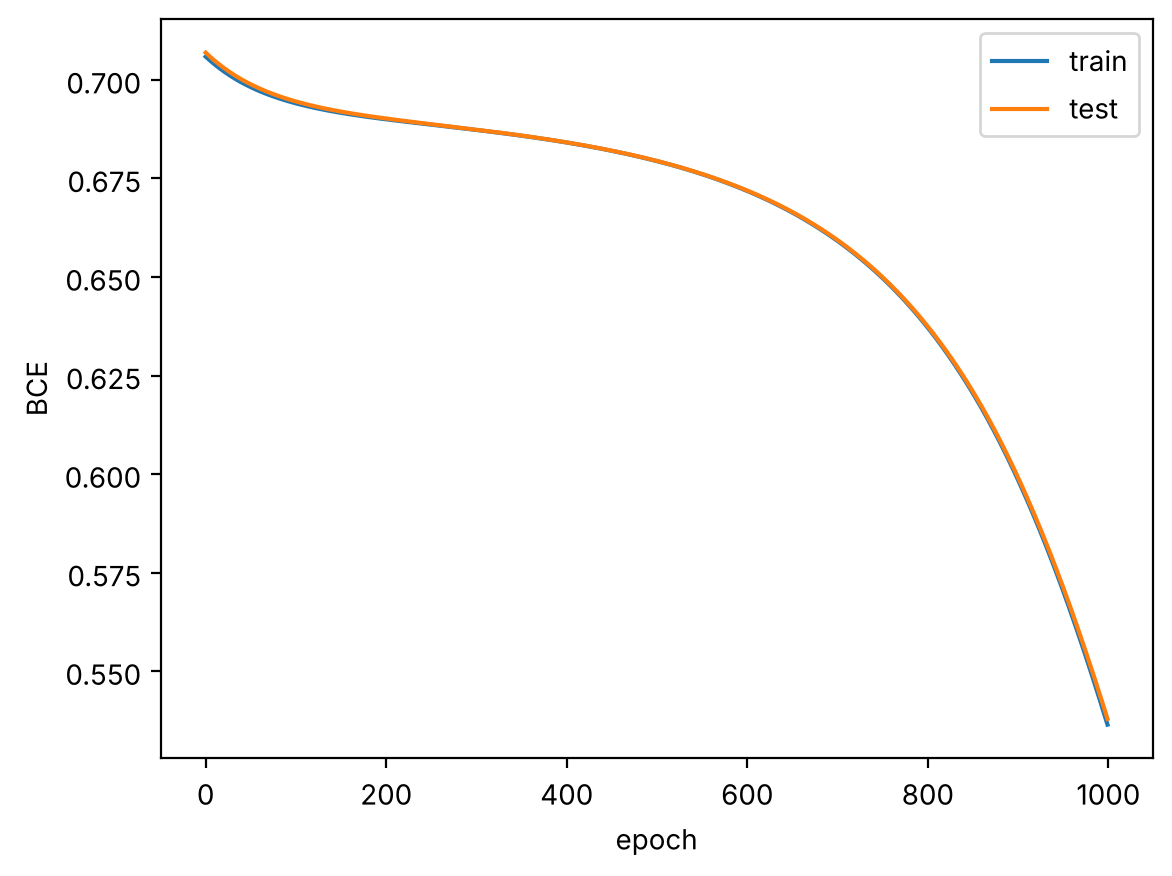

In [6]:
Xd, yd = make_classification(n_samples=10000, n_features=100, n_informative=2, n_redundant=0, n_classes=2, random_state=42)
yd = yd.reshape(-1, 1)
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=42)
print(Xtr.shape, Xte.shape, " majority-class baseline:", round(max(yte.mean(), 1 - yte.mean()), 3))

class DNNClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(100, 10), nn.ReLU(), nn.Linear(10, 20), nn.Tanh(),
                                 nn.Linear(20, 10), nn.SELU(), nn.Linear(10, 1))
    def forward(self, x): return self.net(x)

torch.manual_seed(0)
model = DNNClassifier(); print(model, "\nparameters:", sum(p.numel() for p in model.parameters()))
tr, te, pred = run(model, Xtr, ytr, Xte, yte, lr=0.01, epochs=1000)
print(f"test accuracy {np.mean(pred == yte):.3f}")
print(classification_report(yte, pred)); print(confusion_matrix(yte, pred))
plt.plot(tr, label="train"); plt.plot(te, label="test"); plt.xlabel("epoch"); plt.ylabel("BCE"); plt.legend(); plt.show()

## **Bin packing data (multi-output regression)**

This part of the original notebook needs `Bin_packing.csv`, which is not part of the course folder. The cell below skips the experiment when the file is missing; put the file next to the notebook to run it. Scalers are fitted on the training part only (the original fitted the target scaler on the training part and transformed the test part correctly, which is kept) and the metrics are computed after the inverse transform.

In [7]:
import os, pandas as pd
from sklearn.preprocessing import StandardScaler
if not os.path.exists("Bin_packing.csv"):
    print("Bin_packing.csv not found: skipping this section.")
else:
    from torch.utils.data import TensorDataset, DataLoader
    data = pd.read_csv("Bin_packing.csv")
    Xb_ = data.iloc[:, :11].values.astype(np.float32); yb_ = data.iloc[:, 11:].values.astype(np.float32)
    Xtr, Xte, ytr, yte = train_test_split(Xb_, yb_, test_size=0.10, random_state=42)
    sx, sy = StandardScaler().fit(Xtr), StandardScaler().fit(ytr)
    loader = DataLoader(TensorDataset(t(sx.transform(Xtr)).cpu(), t(sy.transform(ytr)).cpu()), batch_size=32, shuffle=True)
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(11, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, yb_.shape[1])).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3); crit = nn.MSELoss()
    for epoch in range(50):
        for xb, yb2 in loader:
            opt.zero_grad(); crit(net(xb.to(device)), yb2.to(device)).backward(); opt.step()
    with torch.no_grad(): pr = sy.inverse_transform(net(t(sx.transform(Xte))).cpu().numpy())
    print("MSE:", np.mean((pr - yte) ** 2), " MAE:", np.mean(np.abs(pr - yte)))

Bin_packing.csv not found: skipping this section.
